In [163]:
import rdkit
import pandas as pd
from validation import *
from rdkit.Chem import Descriptors, Crippen, Lipinski
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
import numpy as np
import seaborn
import umap
import matplotlib.pyplot as plt
import seaborn as sns

In [164]:
import plotly
import ipywidgets

In [165]:
lst_quants = ['BF16', 'Q8', 'Q6', 'Q4']
lst_models = ['Mistral4-119B', 'Qwen3.6-35B', 'gemma-4-31B', 'gpt-oss-120B']
lst_replicas = range(1,20+1)

# Dados das moléculas do prompt

In [166]:
lst_smiles_prompt = pd.read_csv('smiles_prompt.csv')['SMILES'].values.tolist()

n_smi_total = len(lst_smiles_prompt)
lst_valid_smi = validate_smiles(lst_smiles_prompt)
n_smi_valid = len(lst_valid_smi)
n_tot_violations, n_smi_violations = n_lipinski_violations(lst_valid_smi, threshold=1)
intdiv = calculate_intdiv(lst_valid_smi)

d_prompt = {'n_smi_total':n_smi_total, 'n_smi_valid':n_smi_valid,
            'n_tot_violations':n_tot_violations, 'n_smi_violations':n_smi_violations,
            'intdiv':intdiv}

d_prompt['pct_smi_valid'] = d_prompt['n_smi_valid']/d_prompt['n_smi_total']
d_prompt['pct_lipin_viol'] = d_prompt['n_smi_violations']/d_prompt['n_smi_total']

prompt_pct_smi_valid = d_prompt['pct_smi_valid']
prompt_pct_lipin_viol = d_prompt['pct_lipin_viol']
prompt_intdiv = d_prompt['intdiv']

d_prompt

{'n_smi_total': 69,
 'n_smi_valid': 69,
 'n_tot_violations': 24,
 'n_smi_violations': 0,
 'intdiv': 0.8510483566601391,
 'pct_smi_valid': 1.0,
 'pct_lipin_viol': 0.0}

# TASK 1

In [167]:
path = '/home/ABTLUS/leandro.bortot/repos/gcrm/csv_llms_task_1'

In [168]:
d = {}
for m in lst_models:
    for q in lst_quants:
        for r in lst_replicas:
            lst_smi = pd.read_csv(f'{path}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
            n_smi_total = len(lst_smi)
            lst_valid_smi = validate_smiles(lst_smi)
            n_smi_valid = len(lst_valid_smi)
                
            print(f'{m:15s} {q:5s} {r:2.0f} {n_smi_total:2d} {n_smi_valid:2d}')
            d[f'{m}-{q}-{r}'] = { 'm':m, 'q':q, 'r':r, 'n_smi_total':n_smi_total, 'n_smi_valid':n_smi_valid}

Mistral4-119B   BF16   1 20 19
Mistral4-119B   BF16   2 19 15
Mistral4-119B   BF16   3 19 16
Mistral4-119B   BF16   4 19 19
Mistral4-119B   BF16   5 19 19
Mistral4-119B   BF16   6 20 17
Mistral4-119B   BF16   7  0  0
Mistral4-119B   BF16   8 19 15
Mistral4-119B   BF16   9 19 16
Mistral4-119B   BF16  10 20 20
Mistral4-119B   BF16  11 20 17
Mistral4-119B   BF16  12 21 19
Mistral4-119B   BF16  13 20 16
Mistral4-119B   BF16  14 20 19
Mistral4-119B   BF16  15  0  0
Mistral4-119B   BF16  16 20 14
Mistral4-119B   BF16  17 20 16
Mistral4-119B   BF16  18 19 18
Mistral4-119B   BF16  19 20 15
Mistral4-119B   BF16  20 15 12
Mistral4-119B   Q8     1 20 17
Mistral4-119B   Q8     2  0  0
Mistral4-119B   Q8     3 19 19
Mistral4-119B   Q8     4 20 20
Mistral4-119B   Q8     5 22 18
Mistral4-119B   Q8     6 19 16
Mistral4-119B   Q8     7 22 18
Mistral4-119B   Q8     8 20 20
Mistral4-119B   Q8     9 20 20
Mistral4-119B   Q8    10  1  1
Mistral4-119B   Q8    11 20 17
Mistral4-119B   Q8    12 19 19
Mistral4

In [169]:
df = pd.DataFrame.from_dict(d, orient='index')
df['pct_smi_valid'] = df['n_smi_valid']/df['n_smi_total']
df

,m,q,r,n_smi_total,n_smi_valid,pct_smi_valid
Mistral4-119B-BF16-1,Mistral4-119B,BF16,1,20,19,0.950000
Mistral4-119B-BF16-2,Mistral4-119B,BF16,2,19,15,0.789474
Mistral4-119B-BF16-3,Mistral4-119B,BF16,3,19,16,0.842105
Mistral4-119B-BF16-4,Mistral4-119B,BF16,4,19,19,1.000000
Mistral4-119B-BF16-5,Mistral4-119B,BF16,5,19,19,1.000000
...,...,...,...,...,...,...
gpt-oss-120B-Q4-16,gpt-oss-120B,Q4,16,20,19,0.950000
gpt-oss-120B-Q4-17,gpt-oss-120B,Q4,17,20,19,0.950000
gpt-oss-120B-Q4-18,gpt-oss-120B,Q4,18,20,20,1.000000
gpt-oss-120B-Q4-19,gpt-oss-120B,Q4,19,20,20,1.000000


In [170]:
d_stats = {}
for m in lst_models:
    d_stats[m] = {}
    for q in lst_quants:
        d_stats[m][q] = {}
        
        avg = df.loc[(df['m']==m) & (df['q']==q)]['pct_smi_valid'].mean()
        std = df.loc[(df['m']==m) & (df['q']==q)]['pct_smi_valid'].std()
        d_stats[m][q]['pct_smi_valid'] = (float(avg), float(std))
        

In [171]:
print('-'*39)
print(f'|        MODEL       | pct_smi_valid  |')
print('-'*39)

for m in lst_models:
    for q in lst_quants:
        valid_avg, valid_std = d_stats[m][q]['pct_smi_valid']
        
        print(f'| {m:13s} {q:4s} | {valid_avg*100:5.2f} +- {valid_std*100:5.2f} |')
    print(f'|                    |                |')
print('-'*71)


---------------------------------------
|        MODEL       | pct_smi_valid  |
---------------------------------------
| Mistral4-119B BF16 | 86.47 +-  9.19 |
| Mistral4-119B Q8   | 90.03 +- 13.92 |
| Mistral4-119B Q6   | 87.72 +-  9.61 |
| Mistral4-119B Q4   | 67.57 +- 29.80 |
|                    |                |
| Qwen3.6-35B   BF16 | 95.59 +-  5.58 |
| Qwen3.6-35B   Q8   | 93.75 +-  6.26 |
| Qwen3.6-35B   Q6   | 97.75 +-  3.80 |
| Qwen3.6-35B   Q4   | 95.00 +-  6.69 |
|                    |                |
| gemma-4-31B   BF16 | 90.25 +-  6.58 |
| gemma-4-31B   Q8   | 87.50 +- 10.70 |
| gemma-4-31B   Q6   | 90.75 +-  6.74 |
| gemma-4-31B   Q4   | 92.75 +-  9.66 |
|                    |                |
| gpt-oss-120B  BF16 | 94.00 +-  5.53 |
| gpt-oss-120B  Q8   | 91.75 +-  8.93 |
| gpt-oss-120B  Q6   | 95.50 +-  4.84 |
| gpt-oss-120B  Q4   | 97.00 +-  2.99 |
|                    |                |
-----------------------------------------------------------------------


In [172]:
def n_lipinski_violations(smiles_list, threshold=1):
    n_smi_viol = 0
    n_violations = 0
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        violations = sum([
            Descriptors.MolWt(mol) > 500,
            Crippen.MolLogP(mol) > 5,
            Lipinski.NumHDonors(mol) > 5,
            Lipinski.NumHAcceptors(mol) > 10
        ])
        n_violations += violations

        if violations > threshold:
            n_smi_viol+=1
    return n_violations, n_smi_viol

In [173]:

def calculate_intdiv(smiles_list):
    lst_mol = [Chem.MolFromSmiles(smi) for smi in smiles_list]
    lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
    total = len(lst_mol)

    # Tanimoto Similarity for all unique pairs
    lst_sim = []
    
    for i in range(total):
        for j in range(i + 1, total):
            sim = DataStructs.TanimotoSimilarity(lst_fps[i], lst_fps[j])
            lst_sim.append(sim)
            
    # 3. Diversidade = 1 - Média das Similaridades
    avg_sim = sum(lst_sim) / len(lst_sim)
    int_div = 1.0 - avg_sim
    
    return int_div

# TASK 2

In [174]:
path = '/home/ABTLUS/leandro.bortot/repos/gcrm/csv_llms_task_2'

In [175]:
d = {}
for m in lst_models:
    for q in lst_quants:
        for r in lst_replicas:
            lst_smi = pd.read_csv(f'{path}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
            n_smi_total = len(lst_smi)
            lst_valid_smi = validate_smiles(lst_smi)
            n_smi_valid = len(lst_valid_smi)
            
            if n_smi_valid == 0:
                n_smi_violations = np.nan
                n_tot_violations = np.nan
                intdiv = np.nan
            elif n_smi_valid == 1:
                n_tot_violations, n_smi_violations = n_lipinski_violations(lst_valid_smi, threshold=1)
                
                intdiv = np.nan
            else:
                n_tot_violations, n_smi_violations = n_lipinski_violations(lst_valid_smi, threshold=1)
                intdiv = calculate_intdiv(lst_valid_smi)
                
            print(f'{m:15s} {q:5s} {r:2.0f} {n_smi_total:2d} {n_smi_valid:2d} {n_tot_violations:2.0f} {n_smi_violations:4.0f} {intdiv:5.2f}')
            d[f'{m}-{q}-{r}'] = { 'm':m, 'q':q, 'r':r, 'n_smi_total':n_smi_total, 'n_smi_valid':n_smi_valid,
                                  'n_tot_violations':n_tot_violations, 'n_smi_violations':n_smi_violations,
                                  'intdiv':intdiv}



Mistral4-119B   BF16   1 19  8  4    0  0.75
Mistral4-119B   BF16   2 19  3  0    0  0.83
Mistral4-119B   BF16   3  0  0 nan  nan   nan
Mistral4-119B   BF16   4 19 18  0    0  0.74
Mistral4-119B   BF16   5 19  4  1    0  0.86
Mistral4-119B   BF16   6 20 17  0    0  0.86
Mistral4-119B   BF16   7 19 18  2    0  0.84
Mistral4-119B   BF16   8 19 19  0    0  0.81
Mistral4-119B   BF16   9 19 16  0    0  0.68
Mistral4-119B   BF16  10 19 13  0    0  0.83
Mistral4-119B   BF16  11 19 15  1    0  0.87
Mistral4-119B   BF16  12  0  0 nan  nan   nan
Mistral4-119B   BF16  13 30 17  1    0  0.85
Mistral4-119B   BF16  14 19 15  0    0  0.68
Mistral4-119B   BF16  15 18 17  0    0  0.65
Mistral4-119B   BF16  16 19 16  1    0  0.83
Mistral4-119B   BF16  17 19 12  0    0  0.81
Mistral4-119B   BF16  18 20 15  2    0  0.79
Mistral4-119B   BF16  19 21 17  0    0  0.74
Mistral4-119B   BF16  20 21 21  0    0  0.83
Mistral4-119B   Q8     1 19 15  0    0  0.83
Mistral4-119B   Q8     2  1  1  0    0   nan
Mistral4

In [176]:
df = pd.DataFrame.from_dict(d, orient='index')
df['pct_smi_valid'] = df['n_smi_valid']/df['n_smi_total']
df['pct_lipinski_viol'] = df['n_smi_violations']/df['n_smi_valid']
df['avg_viol_per_smi'] = df['n_tot_violations']/df['n_smi_valid']
df

,m,q,r,n_smi_total,n_smi_valid,n_tot_violations,n_smi_violations,intdiv,pct_smi_valid,pct_lipinski_viol,avg_viol_per_smi
Mistral4-119B-BF16-1,Mistral4-119B,BF16,1,19,8,4.0,0.0,0.751562,0.421053,0.0,0.50
Mistral4-119B-BF16-2,Mistral4-119B,BF16,2,19,3,0.0,0.0,0.827236,0.157895,0.0,0.00
Mistral4-119B-BF16-3,Mistral4-119B,BF16,3,0,0,NaN,NaN,NaN,NaN,NaN,NaN
Mistral4-119B-BF16-4,Mistral4-119B,BF16,4,19,18,0.0,0.0,0.739384,0.947368,0.0,0.00
Mistral4-119B-BF16-5,Mistral4-119B,BF16,5,19,4,1.0,0.0,0.860368,0.210526,0.0,0.25
...,...,...,...,...,...,...,...,...,...,...,...
gpt-oss-120B-Q4-16,gpt-oss-120B,Q4,16,20,15,0.0,0.0,0.681385,0.750000,0.0,0.00
gpt-oss-120B-Q4-17,gpt-oss-120B,Q4,17,20,15,0.0,0.0,0.749012,0.750000,0.0,0.00
gpt-oss-120B-Q4-18,gpt-oss-120B,Q4,18,20,14,0.0,0.0,0.594732,0.700000,0.0,0.00
gpt-oss-120B-Q4-19,gpt-oss-120B,Q4,19,20,19,0.0,0.0,0.824712,0.950000,0.0,0.00


In [177]:
d_stats = {}
for m in lst_models:
    d_stats[m] = {}
    for q in lst_quants:
        d_stats[m][q] = {}
        avg = df.loc[(df['m']==m) & (df['q']==q)]['pct_lipinski_viol'].mean()
        std = df.loc[(df['m']==m) & (df['q']==q)]['pct_lipinski_viol'].std()
        d_stats[m][q]['pct_lipinski_viol'] = (float(avg), float(std))

        avg = df.loc[(df['m']==m) & (df['q']==q)]['intdiv'].mean()
        std = df.loc[(df['m']==m) & (df['q']==q)]['intdiv'].std()
        d_stats[m][q]['intdiv'] = (float(avg), float(std))

        avg = df.loc[(df['m']==m) & (df['q']==q)]['pct_smi_valid'].mean()
        std = df.loc[(df['m']==m) & (df['q']==q)]['pct_smi_valid'].std()
        d_stats[m][q]['pct_smi_valid'] = (float(avg), float(std))

        avg = df.loc[(df['m']==m) & (df['q']==q)]['avg_viol_per_smi'].mean()
        std = df.loc[(df['m']==m) & (df['q']==q)]['avg_viol_per_smi'].std()
        d_stats[m][q]['avg_viol_per_smi'] = (float(avg), float(std))

In [178]:
print('-'*71)
print(f'|        MODEL       | pct_smi_valid  | pct_lipin_viol | intdiv       |')
print('-'*71)

for m in lst_models:
    for q in lst_quants:
        valid_avg, valid_std = d_stats[m][q]['pct_smi_valid']
        viol_avg, viol_std = d_stats[m][q]['pct_lipinski_viol']
        intdiv_avg, intdiv_std = d_stats[m][q]['intdiv']
        
        print(f'| {m:13s} {q:4s} | \
{valid_avg*100:5.2f} +- {valid_std*100:5.2f} | \
{viol_avg*100:5.2f} +- {viol_std*100:5.2f} | \
{intdiv_avg:4.2f} +- {intdiv_std:4.2f} | ')
    print(f'|                    |                |                |              |')

print(f'| Prompt             | {prompt_pct_smi_valid*100:5.2f}         | {prompt_pct_lipin_viol*100:5.2f}          | {prompt_intdiv:4.2f}         |')      
print('-'*71)


-----------------------------------------------------------------------
|        MODEL       | pct_smi_valid  | pct_lipin_viol | intdiv       |
-----------------------------------------------------------------------
| Mistral4-119B BF16 | 73.24 +- 25.09 |  0.00 +-  0.00 | 0.79 +- 0.07 | 
| Mistral4-119B Q8   | 67.34 +- 33.06 |  0.00 +-  0.00 | 0.80 +- 0.06 | 
| Mistral4-119B Q6   | 53.29 +- 25.22 |  0.00 +-  0.00 | 0.80 +- 0.04 | 
| Mistral4-119B Q4   | 44.12 +- 30.14 |  0.49 +-  2.02 | 0.82 +- 0.03 | 
|                    |                |                |              |
| Qwen3.6-35B   BF16 | 81.75 +- 14.07 | 10.89 +- 12.79 | 0.74 +- 0.05 | 
| Qwen3.6-35B   Q8   | 82.00 +- 18.17 |  7.30 +- 14.57 | 0.72 +- 0.08 | 
| Qwen3.6-35B   Q6   | 68.25 +- 29.70 |  6.59 +- 12.37 | 0.68 +- 0.11 | 
| Qwen3.6-35B   Q4   | 71.91 +- 23.99 |  6.27 +-  9.70 | 0.68 +- 0.08 | 
|                    |                |                |              |
| gemma-4-31B   BF16 | 92.75 +-  8.96 |  6.87 +-  5.60 |

# Chemical Space

In [179]:
d = {}
for m in lst_models:
    d[m] = {}

    for q in lst_quants:
        d[m][q] = []

        for r in lst_replicas:
            lst_smi = pd.read_csv(f'{path}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
            lst_valid_smi = validate_smiles(lst_smi)
            d[m][q] += lst_valid_smi

In [180]:
d['gpt-oss-120B']['Q4']

['CC(C)C(=O)S(=O)c1cccc(NC2=NC(Nc3ccccc3)C2)c1',
 'CC(C)C(=O)S(=O)c1cccc(NC2=NC(Nc3cccnc3)C2)c1',
 'CN(C)CCOS(=O)c1cccc(NC2=NC(Nc3cccnc3)C2)c1',
 'CN1CCN(S(=O)c2cccc(NC3=NC(Nc4ccccc4)C3)c2)CC1',
 'O=C(C(Cl)Cl)S(=O)c1cccc(NC2=NC(Nc3ccccc3)C2)c1',
 'O=C(Nc1ccccc1)c1nc2ccccc2[nH]1',
 'N#CC1=CC(F)=C(NC(=O)c2ncncn2)C1',
 'O=C(Nc1ccccc1)c1ccc(F)cc1',
 'CN1CCN(C(=O)c2ccccc2)CC1',
 'O=C(c1ccccc1)N1CCCC1',
 'O=C(CNCCN[SH](=O)=O)c1ccccc1',
 'C=Cc1ccccc1O',
 'Clc1ccccc1Cl',
 'O=C(Nc1ncncn1)c1ccccc1',
 'CNC(=O)c1ccccc1',
 'CCN(CC)C(=O)c1ccccc1',
 'O=C(CNCCO)c1ccccc1',
 'O=C(CNCCNS(=O)(=O)c1ccccc1)c1ccccc1',
 'COc1ccc(NC(=O)N(C)C)cc1',
 'O=C(Nc1ccc(Cl)cc1)C1CCNCC1',
 'CN(C)S(=O)(=O)c1ccc(N2CCN(C(=O)Nc3cc(C(F)(F)F)ccc3Cl)CC2)cc1',
 'O=C(Nc1ccc(F)cc1)N1CCOCC1',
 'CN1CCN(C(=O)c2ccc(F)cc2)CC1',
 'O=C(NC1=CN=C2N=CN=C12)c1ccccc1',
 'O=S(=O)(c1ccc(F)cc1)N1CCOCC1',
 'O=C(c1ccccc1)N1CCCC1',
 'O=C(c1ccccc1)N1CCNCC1',
 'N#Cc1ccc(C(=O)NCCN)cc1',
 'Nc1ccc(S(=O)(=O)C2CCCCCC2)cc1',
 'OCCOc1ccccc1',
 'O=C(Nc1ccc(C

In [181]:
d.keys()

dict_keys(['Mistral4-119B', 'Qwen3.6-35B', 'gemma-4-31B', 'gpt-oss-120B'])

/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


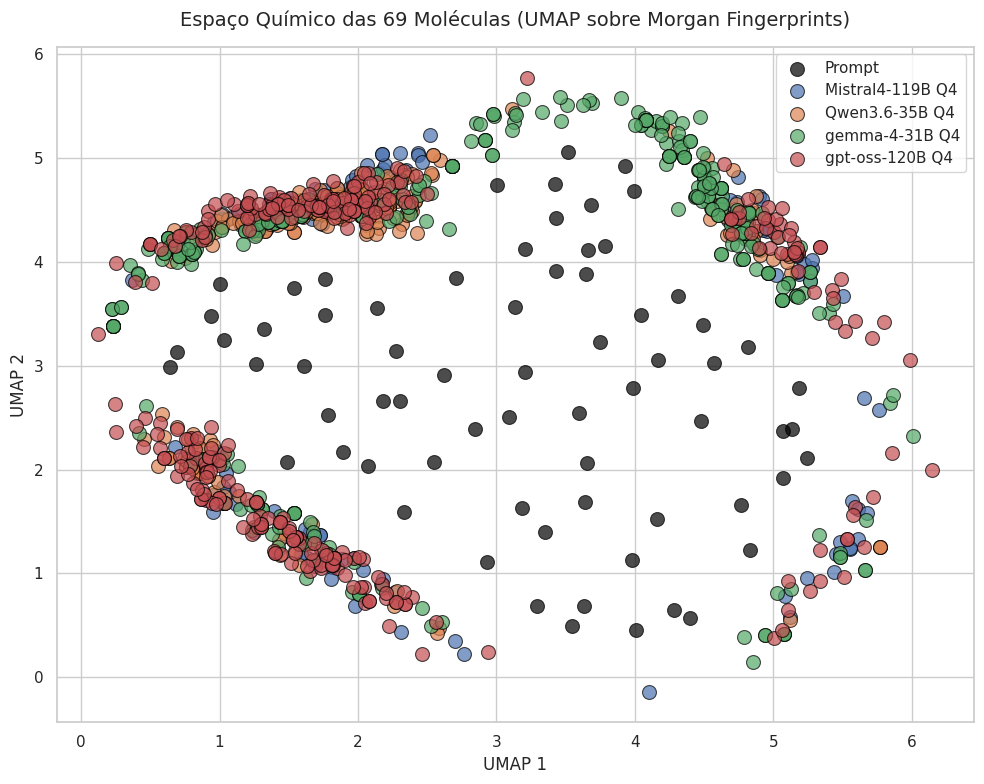

In [182]:
#import pandas as pd
#import numpy as np
#import matplotlib.pyplot as plt
#import seaborn as sns
#from rdkit import Chem
#from rdkit.Chem import AllChem
#import umap

reducer = umap.UMAP(
    n_neighbors=15,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
    min_dist=0.1,      # Controla o quão agrupados os pontos ficam no gráfico
    metric='jaccard',  # Ideal para fingerprints binários
    random_state=42    # Para reprodutibilidade
)


lst_mols = [Chem.MolFromSmiles(m) for m in lst_smiles_prompt if m]
lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]

embedding_ref = reducer.fit_transform(lst_fps)
df_ref = pd.DataFrame(embedding_ref, columns=['UMAP_1', 'UMAP_2'])

plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão
scatter = sns.scatterplot(data=df_ref, x='UMAP_1', y='UMAP_2', s=100, alpha=0.7, color='black', edgecolor='black', label='Prompt')

# ---------------------------------------------------------------------------

for model in d:
    lst_mols = [Chem.MolFromSmiles(m) for m in d[model]['Q4'] if m]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]
    embedding_comp = reducer.transform(lst_fps)
    df_comp = pd.DataFrame(embedding_comp, columns=['UMAP_1', 'UMAP_2'])

    scatter = sns.scatterplot(data=df_comp, x='UMAP_1', y='UMAP_2', s=100, alpha=0.7, edgecolor='black', label=model+' Q4')


# ---------------------------------------------------------------------------




plt.title('Espaço Químico das 69 Moléculas (UMAP sobre Morgan Fingerprints)', fontsize=14, pad=15)
plt.xlabel('UMAP 1', fontsize=12)
plt.ylabel('UMAP 2', fontsize=12)

# (Opcional) Adicionar rótulos em alguns pontos
# Descomente o bloco abaixo se quiser ver os IDs em cima dos pontos
# for i in range(df.shape[0]):
#     plt.text(df['UMAP_1'][i] + 0.1, df['UMAP_2'][i] + 0.1, 
#              df['ID'][i], fontsize=8, alpha=0.7)

plt.tight_layout()
plt.show()

In [183]:
prev_a = 0
prev_b = 69

print('prompt ', prev_a, prev_b)
for m in lst_models:
    l = len(d[m]['Q4'])
    a = prev_b
    b = a + l
    print(l, m, a, b )
    prev_a = a
    prev_b = b

prompt  0 69
142 Mistral4-119B 69 211
289 Qwen3.6-35B 211 500
375 gemma-4-31B 500 875
325 gpt-oss-120B 875 1200


{'Mistral4-119B': {'BF16': ['CCN1CCN(C2=CC=C(F)C=Cc3cc4c(ncnc4c4ccccc34)N2)CC1', 'N#Cc1ccc(Nc2ncnc3ccc(Oc4ccccc4)cc23)cc1', 'Clc1ccc(Nc2ncnc3c2cc(OCCN2CCCC2)c2ccccc23)cc1', 'O=C(Nc1ccc(-c2ccccc2)cc1)c1ccccc1', 'N#Cc1ccc(Nc2ccc(-c3ccccc3)cn2)cc1', 'O=C(Nc1ccc(-c2ccccc2)cc1)c1cccc2ccc-2cc1', 'N#Cc1ccc(Nc2ncnc3ccc(-c4ccc(O)cc4)cc23)cc1', 'Brc1ccc(Nc2ccc(-c3ccc(Br)cc3)cn2)cc1', 'O=[SH](Nc1ccccc1)(Nc1ccc(F)cc1)c1ccccc1', 'CS(=O)(=O)N1C=CC=Cc2ccccc21', 'Nc1cccnc1[SH](=O)(c1ccccc1)c1ccccc1', 'O=CNC1=CC=CC2=C(C1)N(c1ccccc1)C2', 'O=c1cc(N2CCN(Cc3ccccc3)CC2)c2ccccc2[nH]1', 'CNC1=CC=CC2=C(C1)N(c1ccccc1)C2=O', 'O=C(NCc1ccccc1)c1ccc2c(-c3ccccc3)ncncc1-2', 'N#CC1=CC=CC2=C(C1)N(c1ccccc1)C2', 'O=c1[nH]c2c(n1-c1ccccc1)CC(F)=CC=C2', 'O=S(Nc1ccccc1)N1CCN(c2ccccc2)CC1', 'CNC1=CC=CC2=C(C1)N(c1ccccc1)C(=O)C2', 'O=C1CN(c2ccccc2)c2ccccc21', 'O=C(Nc1ccccc1)N1CCC(c2ccccc2)CC1', 'O=C1CC2=C(CC(F)=CC=C2)N1c1ccccc1', 'NC(=O)C1=CC=CC2=C(C1)N(c1ccccc1)C2', 'N#CC1=CC=Cc2[nH]c(=O)n(-c3ccccc3)c2C1', 'O=C1CN(c2ccccc2F)c2

/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


142 Mistral4-119B 69 211
289 Qwen3.6-35B 211 500
375 gemma-4-31B 500 875
325 gpt-oss-120B 875 1200
142 Mistral4-119B 69 211
289 Qwen3.6-35B 211 500
375 gemma-4-31B 500 875
325 gpt-oss-120B 875 1200


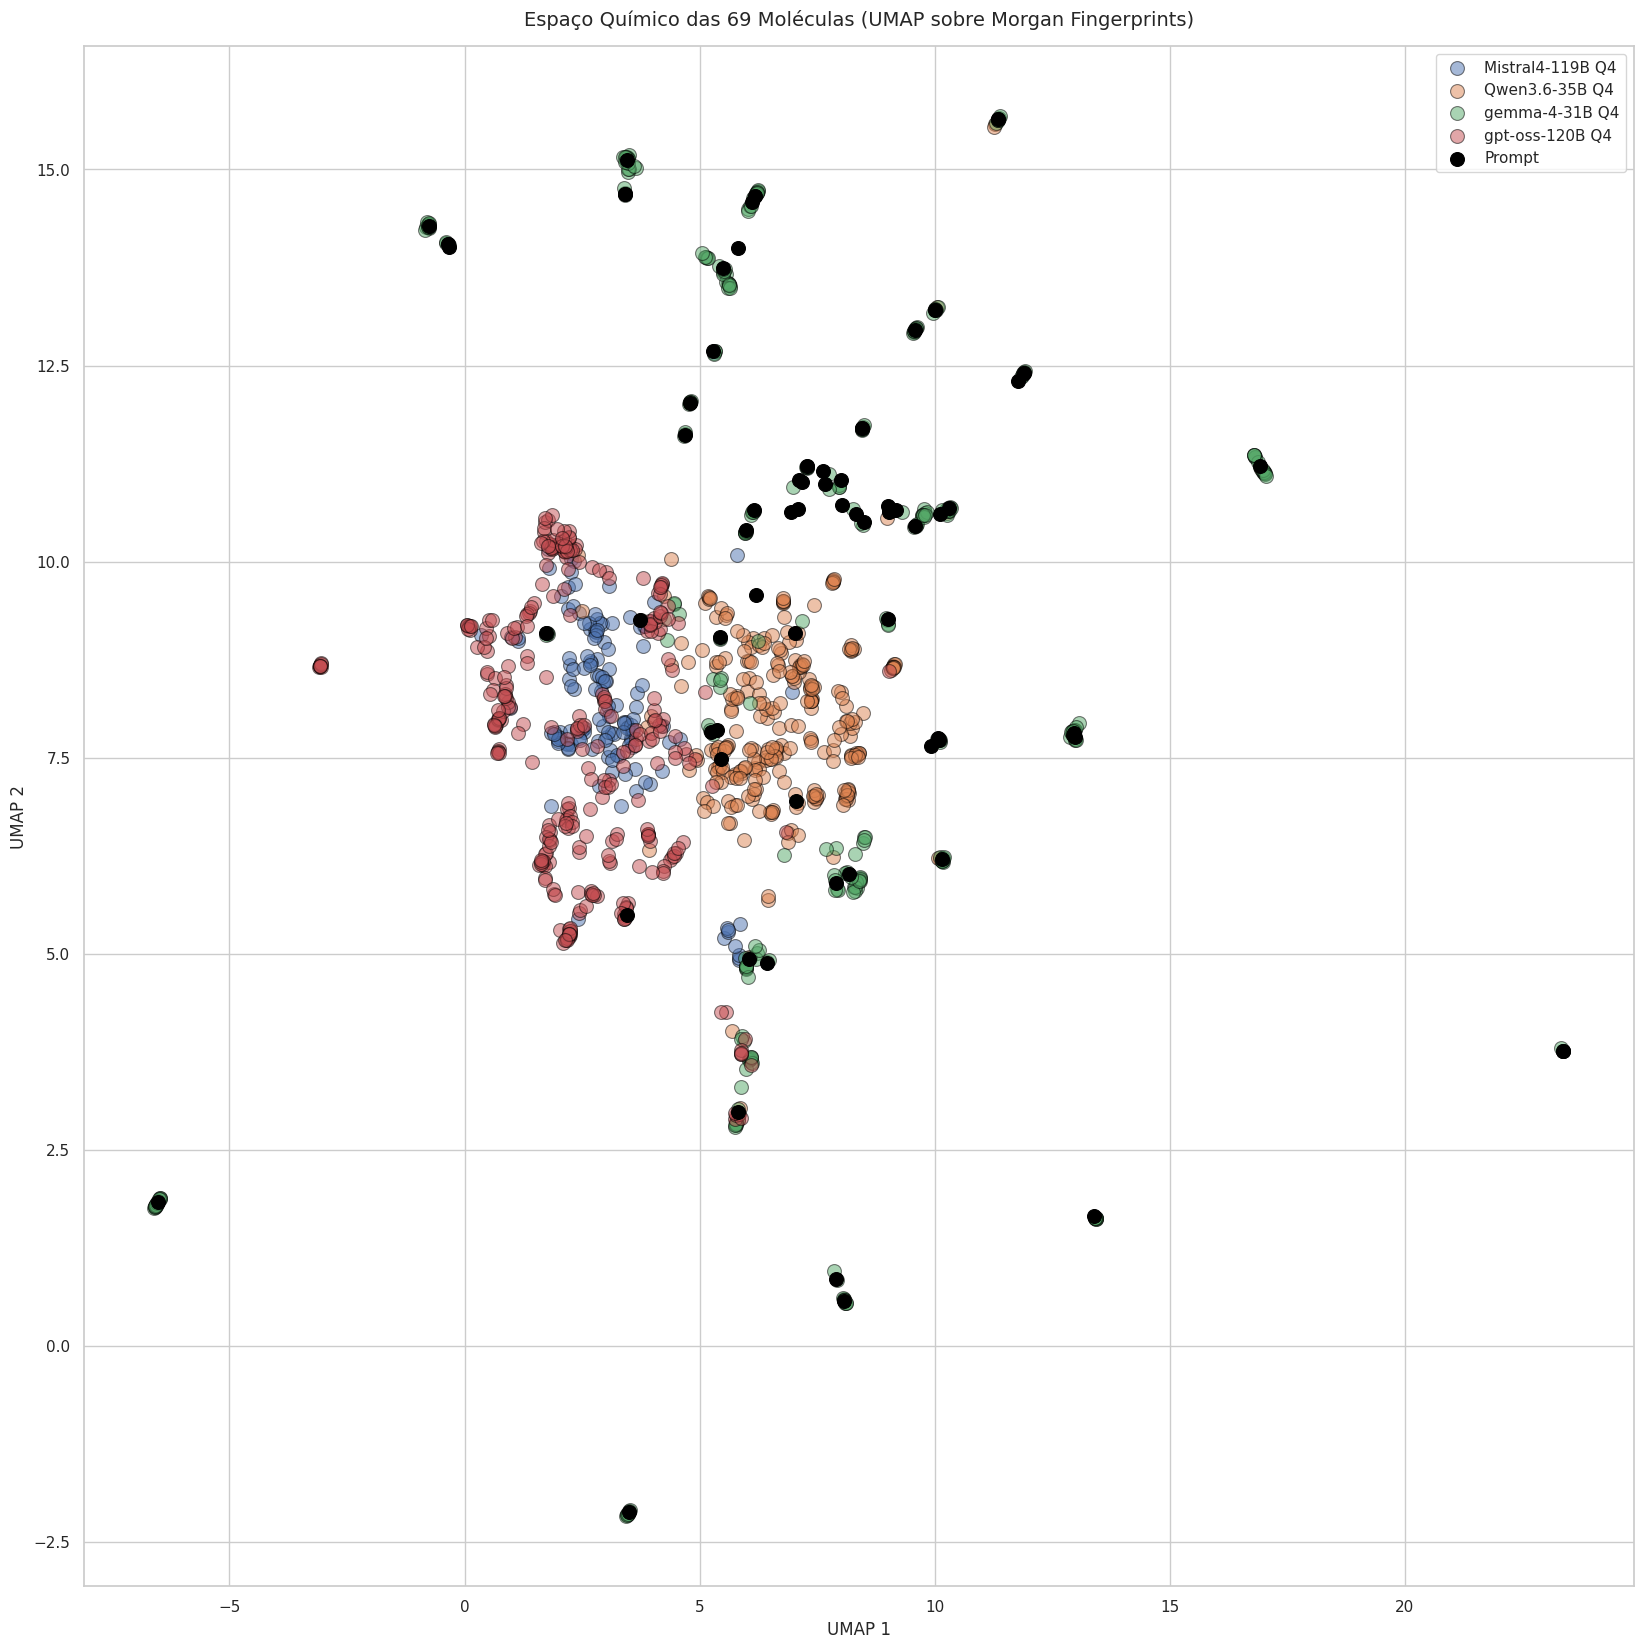

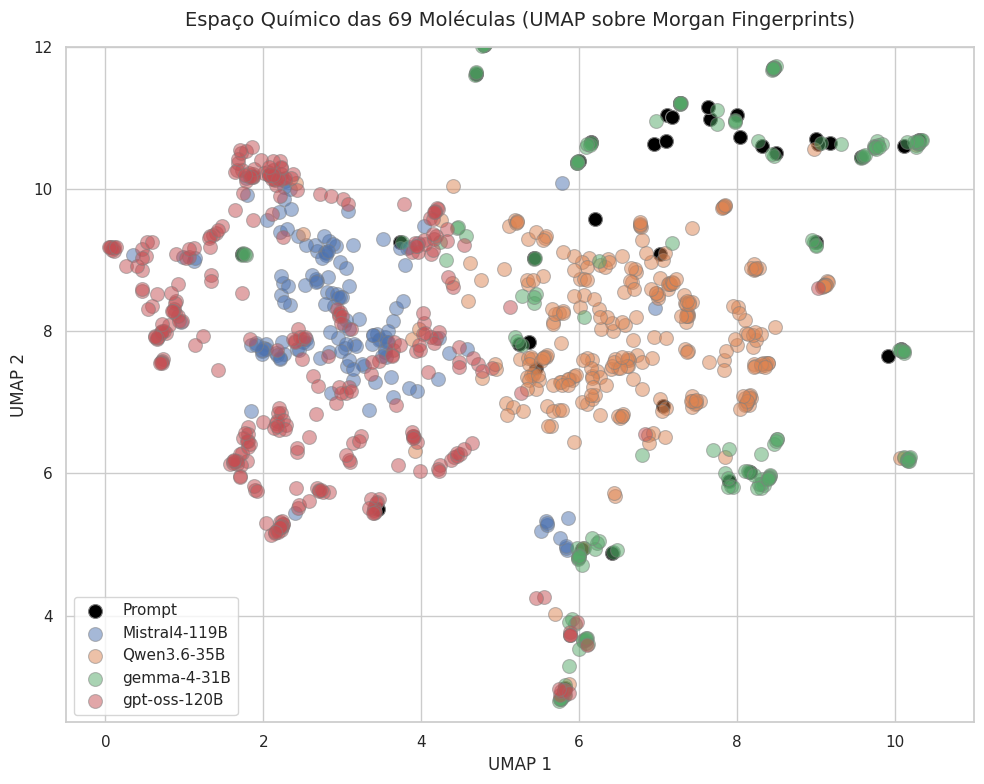

In [184]:
#import pandas as pd
#import numpy as np
#import matplotlib.pyplot as plt
#import seaborn as sns
#from rdkit import Chem
#from rdkit.Chem import AllChem
#import umap

q='Q4'

reducer = umap.UMAP(
    n_neighbors=15,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
    min_dist=0.1,      # Controla o quão agrupados os pontos ficam no gráfico
    metric='jaccard',  # Ideal para fingerprints binários
    random_state=42    # Para reprodutibilidade
)
print(d)


lst_smiles = lst_smiles_prompt.copy()
for model in lst_models:
    lst_smiles += d[model][q]
    
print(len(lst_smiles))

lst_mols = [Chem.MolFromSmiles(m) for m in lst_smiles if m]
lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]

embedding = reducer.fit_transform(lst_fps)
df = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])

plt.figure(figsize=(20,20))
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão

prev_a = 0
prev_b = 69
for m in lst_models:
    l = len(d[m]['Q4'])
    a = prev_b
    b = a + l
    print(l, m, a, b )
    prev_a = a
    prev_b = b
    scatter = sns.scatterplot(data=df[a:b], x='UMAP_1', y='UMAP_2', s=100, alpha=0.5,  edgecolor='black', label=f'{m} {q}')
scatter = sns.scatterplot(data=df[0:69], x='UMAP_1', y='UMAP_2', s=100, alpha=1.0, color='black', edgecolor='black', label='Prompt')



plt.title('Espaço Químico das 69 Moléculas (UMAP sobre Morgan Fingerprints)', fontsize=14, pad=15)
plt.xlabel('UMAP 1', fontsize=12)
plt.ylabel('UMAP 2', fontsize=12)




plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")

# Criar o gráfico de dispersão
scatter = sns.scatterplot(data=df[0:69], x='UMAP_1', y='UMAP_2', s=100, alpha=1.0, color='black', edgecolor='gray', label='Prompt')

prev_a = 0
prev_b = 69
for m in lst_models:
    l = len(d[m]['Q4'])
    a = prev_b
    b = a + l
    print(l, m, a, b )
    prev_a = a
    prev_b = b
    scatter = sns.scatterplot(data=df[a:b], x='UMAP_1', y='UMAP_2', s=100, alpha=0.5,  edgecolor='gray', label=m)



plt.title('Espaço Químico das 69 Moléculas (UMAP sobre Morgan Fingerprints)', fontsize=14, pad=15)
plt.ylim([2.5,12])
plt.xlim([-0.5,11])
plt.xlabel('UMAP 1', fontsize=12)
plt.ylabel('UMAP 2', fontsize=12)

# (Opcional) Adicionar rótulos em alguns pontos
# Descomente o bloco abaixo se quiser ver os IDs em cima dos pontos
# for i in range(df.shape[0]):
#     plt.text(df['UMAP_1'][i] + 0.1, df['UMAP_2'][i] + 0.1, 
#              df['ID'][i], fontsize=8, alpha=0.7)

plt.tight_layout()
plt.show()

In [185]:
import pandas as pd
import plotly.graph_objects as go
from rdkit import Chem
from rdkit.Chem import AllChem
import umap
import ipywidgets as widgets
from IPython.display import display

# (Assumindo que lst_smiles_prompt, lst_models e o dicionário 'd' já estão na memória)

# ==========================================
# 1. FUNÇÕES AUXILIARES DE PROCESSAMENTO
# ==========================================
def calcular_dados(q_val, n_vizinhos):
    """Gera a lista unificada de SMILES, calcula os Fingerprints e roda o UMAP."""
    # 1. Reconstruir a lista de SMILES
    smiles_atuais = lst_smiles_prompt.copy()
    for m in lst_models:
        smiles_atuais += d[m][q_val]
        
    # 2. Recalcular Moléculas e Fingerprints
    mols = [Chem.MolFromSmiles(m) for m in smiles_atuais if m]
    fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in mols]
    
    # 3. Rodar UMAP
    reducer = umap.UMAP(n_neighbors=n_vizinhos, min_dist=0.1, metric='jaccard', random_state=42)
    embedding_atual = reducer.fit_transform(fps)
    
    return smiles_atuais, embedding_atual

# ==========================================
# 2. CONFIGURAÇÃO INICIAL
# ==========================================
q_inicial = 'Q4'
n_inicial = 15

# Calcula o estado inicial
smiles_base, embedding_base = calcular_dados(q_inicial, n_inicial)

fig = go.FigureWidget()

# --- TRACE 0: Prompt (Sempre os primeiros 69) ---
fig.add_trace(go.Scatter(
    x=embedding_base[0:69, 0], y=embedding_base[0:69, 1], mode='markers', name='Prompt',
    marker=dict(size=18, color='black', opacity=1.0, line=dict(width=1.5, color='gray')),
    text=[f"<b>ID:</b> Molecule_{i}<br><b>SMILES:</b> {smiles_base[i]}" for i in range(69)],
    hoverinfo="text"
))

# --- TRACES SEGUINTES: Modelos ---
prev_b = 69
for m in lst_models:
    l = len(d[m][q_inicial])
    a = prev_b
    b = a + l
    fig.add_trace(go.Scatter(
        x=embedding_base[a:b, 0], y=embedding_base[a:b, 1], mode='markers', name=f'{m} ({q_inicial})',
        marker=dict(size=10, opacity=1.0, line=dict(width=1, color='white')),
        text=[f"<b>ID:</b> Molecule_{i}<br><b>SMILES:</b> {smiles_base[i]}" for i in range(a, b)],
        hoverinfo="text"
    ))
    prev_b = b

# Layout base do gráfico
fig.update_layout(
    font=dict(size=14),
    title={
        'text': 'Espaço Químico (Ajuste Interativo do UMAP e Quantização)',
        'y': 0.95, 'x': 0.5, 'xanchor': 'center', 'yanchor': 'top',
        'font': dict(size=16, color='#2c3e50')
    },
    plot_bgcolor='white', paper_bgcolor='white', hovermode='closest', width=950, height=750,
    xaxis=dict(title='UMAP 1', gridcolor='#e2e8f0', zerolinecolor='#cbd5e1'),
    yaxis=dict(title='UMAP 2', gridcolor='#e2e8f0', zerolinecolor='#cbd5e1'),
    legend=dict(title="Fontes / Modelos", yanchor="top", y=1, xanchor="left", x=1.02, 
                bgcolor="rgba(255, 255, 255, 0.85)", bordercolor="#cbd5e1", borderwidth=1)
)

# ==========================================
# 3. WIDGETS E CALLBACK DE ATUALIZAÇÃO
# ==========================================
# Menu Dropdown para a variável Q
dropdown_q = widgets.Dropdown(
    options=['BF16', 'Q8', 'Q6', 'Q4'],
    value=q_inicial,
    description='Variável Q:',
    style={'description_width': 'initial'}
)

# Caixa de texto numérico para o n_neighbors
input_neighbors = widgets.BoundedIntText(
    value=n_inicial, min=2, max=200, step=1,
    description='n_neighbors:',
    style={'description_width': 'initial'},
    continuous_update=False 
)

def atualizar_grafico(*args):
    # Pega os valores atuais dos widgets
    q_atual = dropdown_q.value
    n_atual = input_neighbors.value
    
    # Recalcula tudo (Moléculas, Fingerprints e UMAP)
    novos_smiles, novo_embedding = calcular_dados(q_atual, n_atual)
    
    # Atualiza o gráfico de forma silenciosa
    with fig.batch_update():
        # Atualiza o Prompt
        fig.data[0].x = novo_embedding[0:69, 0]
        fig.data[0].y = novo_embedding[0:69, 1]
        
        # Atualiza os modelos subsequentes
        prev_b_loop = 69
        for i, m in enumerate(lst_models):
            l = len(d[m][q_atual])
            a = prev_b_loop
            b = a + l
            
            # Atualiza coordenadas
            fig.data[i+1].x = novo_embedding[a:b, 0]
            fig.data[i+1].y = novo_embedding[a:b, 1]
            # Atualiza o texto do hover (SMILES mudaram)
            fig.data[i+1].text = [f"<b>ID:</b> Molecule_{j}<br><b>SMILES:</b> {novos_smiles[j]}" for j in range(a, b)]
            # Atualiza o nome da legenda para refletir o 'q' atual
            fig.data[i+1].name = f'{m} ({q_atual})'
            
            prev_b_loop = b

# Conecta os widgets à função de atualização
dropdown_q.observe(atualizar_grafico, names='value')
input_neighbors.observe(atualizar_grafico, names='value')

# ==========================================
# 4. EXIBIR TUDO NA TELA
# ==========================================
# Organiza os controles lado a lado (HBox) acima do gráfico
painel_controles = widgets.HBox([dropdown_q, input_neighbors])
display(widgets.VBox([painel_controles, fig]))

/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [255]:
def get_data(path='/home/ABTLUS/leandro.bortot/repos/gcrm/csv_llms_task_2'):
    d = {}
    for m in lst_models:
        d[m] = {}

        for q in lst_quants:
            d[m][q] = []

            for r in lst_replicas:
                lst_smi = pd.read_csv(f'{path}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
                lst_valid_smi = validate_smiles(lst_smi)
                d[m][q] += lst_valid_smi
    return d

In [275]:
def calc_umap(d_smiles, q, n_neighbors=15):

    reducer = umap.UMAP(
        n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
        min_dist=0.1,      # Controla o quão agrupados os pontos ficam no gráfico
        metric='jaccard',  # Ideal para fingerprints binários
        random_state=42    # Para reprodutibilidade
    )


    lst_smiles = lst_smiles_prompt.copy()
    for model in lst_models:
        lst_smiles += d_smiles[model][q]
        
    print(len(lst_smiles))

    lst_mols = [Chem.MolFromSmiles(m) for m in lst_smiles if m]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mols]

    embedding = reducer.fit_transform(lst_fps)


    i=0
    lst_index  = ['prompt']*69
    i+=1
    for m in lst_models:
        lst_index += [m]*len(d_smiles[m][q])
        i+=1


    df = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])
    df['model'] = lst_index

    return df

In [327]:
def distance(x0,y0,x1,y1):
    return float(np.sqrt( np.power((x0-x1),2)+np.power((y0-y1),2) ))


def calc_dists(df_umap):
    coords_ref = df_umap.loc[df_umap['model']=='prompt'][['UMAP_1','UMAP_2']].values.tolist()

    d_dist = {}

    for model in lst_models:
        d_dist[model] = {}
        d_dist[model]['all'] = []
        d_dist[model]['avg'] = []
        d_dist[model]['min'] = []

        # Get its coordinates
        coords_model = df_umap.loc[df_umap['model']==model][['UMAP_1','UMAP_2']].values.tolist()

        # For each molecule generated by each model...
        for x1,y1 in coords_model:
            lst_dist_mol = []
            for x0,y0 in coords_ref:
                # Distance between each molecule from the model and from the prompt
                d = float(distance(x0,y0,x1,y1))
                lst_dist_mol.append(d)

            # model-promt distances
            d_dist[model]['all'] += lst_dist_mol
            d_dist[model]['avg'].append(float(np.average(np.array(lst_dist_mol))))
            d_dist[model]['min'].append(float(np.min(np.array(lst_dist_mol))))


        #for model in lst_models:
            #print(model, len(d_dist['all'][model]), len(d_dist['min'][model]), len(d_dist['avg'][model]))
    return d_dist

In [329]:
n_neighbors=15

d_stats_df = {}
d_dist_stats = {}
d_dist = {}

for q in lst_quants:
    d_dist_stats[q] = {}
    d_dist[q] = {}

    d_smiles = get_data()
    df = calc_umap(d_smiles=d_smiles, q=q, n_neighbors=n_neighbors)
    d_dist[q] = calc_dists(df_umap=df)

    for model in lst_models:
        d_dist_stats[q][model] = {}
        
        for stats in ['all', 'avg', 'min']:
            d_dist_stats[q][model][f'{stats} avg'] = np.average(d_dist[q][model][stats])
            d_dist_stats[q][model][f'{stats} std'] = np.std(d_dist[q][model][stats])
            d_dist_stats[q][model][f'{stats} min'] = np.min(d_dist[q][model][stats])

    d_stats_df[q] = pd.DataFrame.from_dict(d_dist_stats[q], orient='index')


1372


/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


1354


/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


1273


/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


1200


/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1887: UserWarning: gradient function is not yet implemented for jaccard distance metric; inverse_transform will be unavailable
  warn(
/media/data/miniconda3/envs/AIchemist/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [330]:
for q in lst_quants:
    print(q)
    display(d_stats_df[q].style.format("{:.2f}"))

BF16


,all avg,all std,all min,avg avg,avg std,avg min,min avg,min std,min min
Mistral4-119B,5.83,3.78,0.01,5.83,0.49,5.14,1.05,0.61,0.01
Qwen3.6-35B,6.63,4.48,0.00,6.63,1.66,5.28,0.62,0.40,0.00
gemma-4-31B,8.43,5.15,0.00,8.43,3.09,5.08,0.16,0.23,0.00
gpt-oss-120B,7.94,4.96,0.00,7.94,2.83,5.14,0.42,0.44,0.00


Q8


,all avg,all std,all min,avg avg,avg std,avg min,min avg,min std,min min
Mistral4-119B,5.90,3.59,0.06,5.90,0.74,5.23,0.85,0.40,0.06
Qwen3.6-35B,5.99,3.75,0.02,5.99,1.27,5.22,0.52,0.36,0.02
gemma-4-31B,8.31,4.80,0.00,8.31,2.74,5.23,0.18,0.24,0.00
gpt-oss-120B,7.66,4.53,0.01,7.66,2.43,5.25,0.34,0.34,0.01


Q6


,all avg,all std,all min,avg avg,avg std,avg min,min avg,min std,min min
Mistral4-119B,6.44,5.36,0.03,6.44,0.65,5.80,0.52,0.24,0.03
Qwen3.6-35B,7.76,5.63,0.00,7.76,1.16,5.65,0.91,0.59,0.00
gemma-4-31B,10.20,6.80,0.00,10.20,4.70,5.62,0.18,0.24,0.00
gpt-oss-120B,9.08,6.17,0.00,9.08,3.52,5.66,0.32,0.34,0.00


Q4


,all avg,all std,all min,avg avg,avg std,avg min,min avg,min std,min min
Mistral4-119B,6.69,3.15,0.03,6.69,0.53,4.80,1.10,0.45,0.03
Qwen3.6-35B,5.25,3.19,0.02,5.25,0.63,4.48,0.68,0.35,0.02
gemma-4-31B,7.60,4.74,0.00,7.60,3.06,4.47,0.12,0.18,0.00
gpt-oss-120B,7.38,3.32,0.02,7.38,1.10,4.93,1.25,0.77,0.02


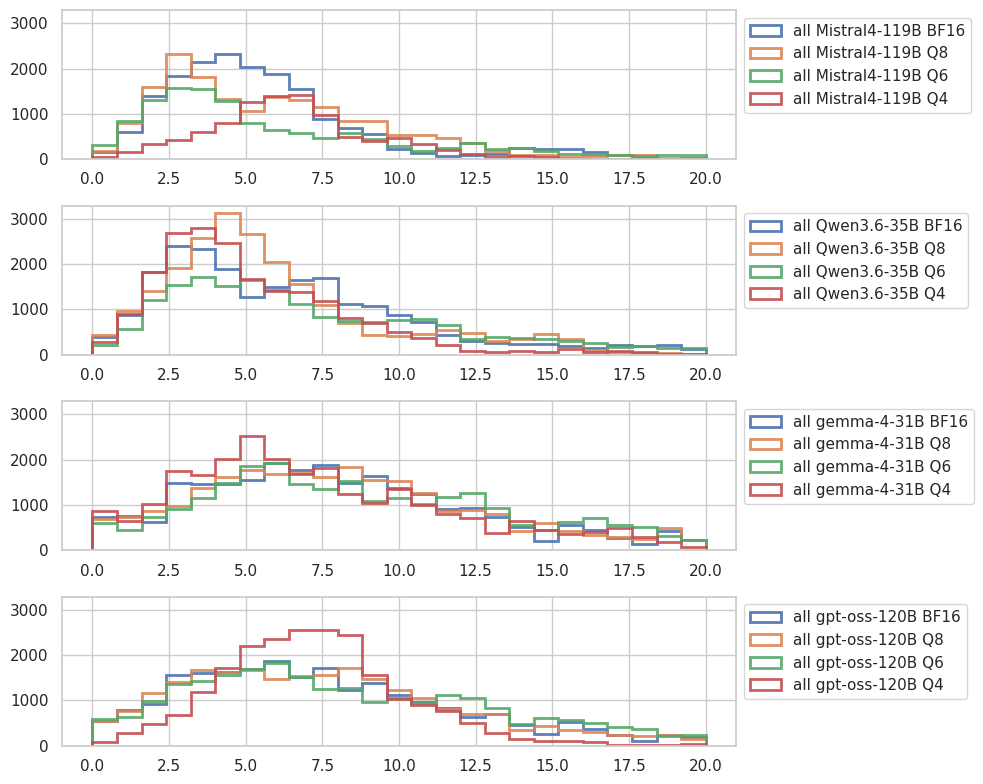

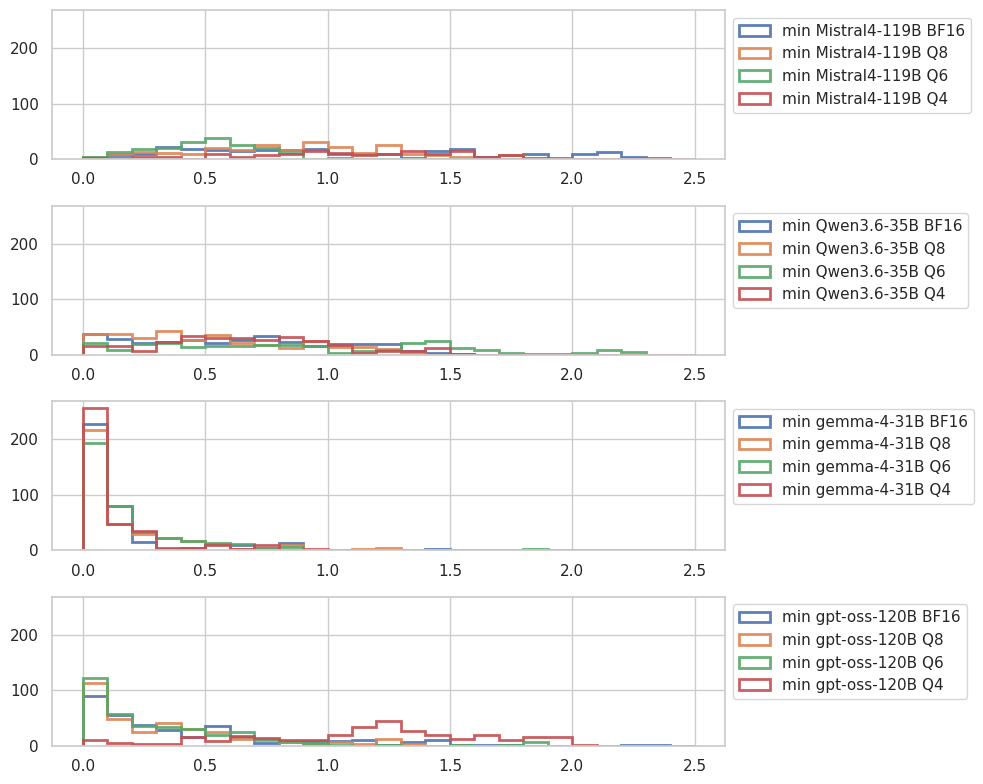

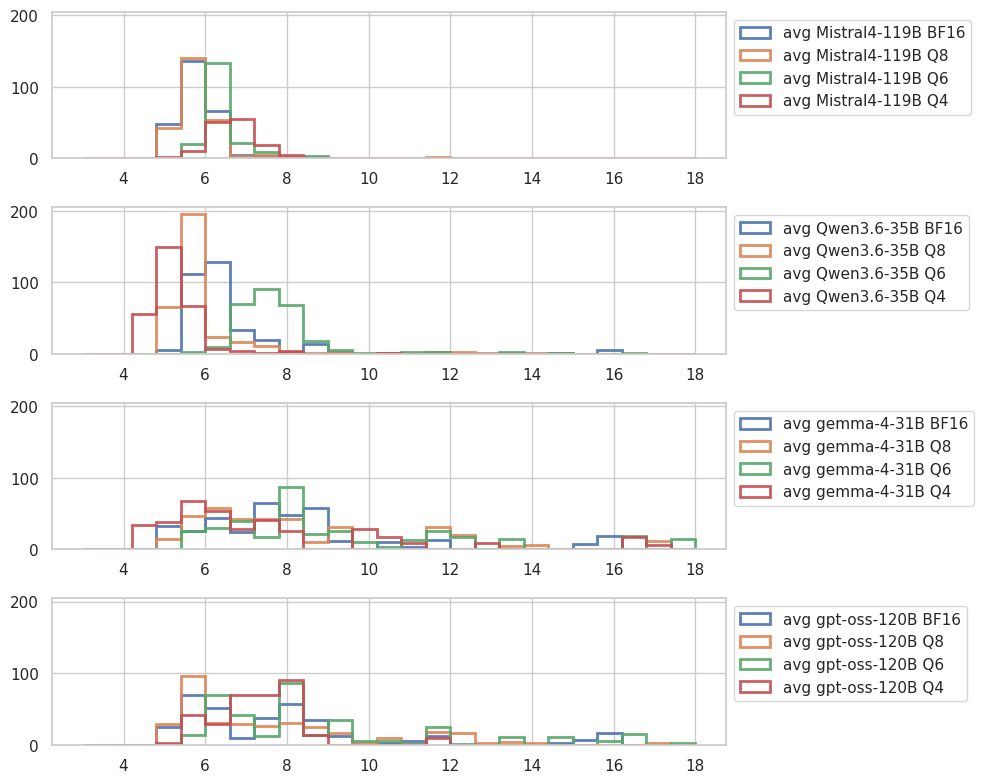

In [366]:
bins = 25

d_yminmax = {'all':(0,20), 'min':(0,2.5), 'avg':(3,18)}

for stats in ['all', 'min', 'avg']:
    fig, ax = plt.subplots(len(lst_models), 1, figsize=(10, 8), sharey=True)
    for q in lst_quants:
        for i,model in enumerate(lst_models):
            ax[i].hist(d_dist[q][model][stats], label=f'{stats} {model} {q}', range=d_yminmax[stats], bins=bins, alpha=0.9, histtype='step', linewidth=2)
            ax[i].legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.tight_layout()
    plt.show()

